# 01 · Official folds and spectrograms

Checks that the ESC-50 folds are used exactly as published, then shows one clip per class group with its waveform and log-mel spectrogram, computed by the same front end the model trains on (`configs/baseline.yaml`).

Run from the repository root after `python -m audioscope.data.download`.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from audioscope.config import load_config
from audioscope.data import load_esc50, split_indices
from audioscope.features import FeatureConfig, LogMel, fix_length, load_audio
from audioscope.viz import plot_logmel, plot_waveform

cfg = load_config("configs/baseline.yaml")
fcfg = FeatureConfig.from_dict(cfg["features"])
cat = load_esc50(cfg["dataset"]["root"])
meta = pd.read_csv(Path(cfg["dataset"]["root"]) / "meta" / "esc50.csv")
print(len(cat), "clips,", cat.num_classes, "classes,", cat.num_folds, "folds")

2000 clips, 50 classes, 5 folds


## Fold sizes and class balance

In [2]:
counts = pd.crosstab(meta["category"], meta["fold"])
print("clips per fold:", meta["fold"].value_counts().sort_index().to_dict())
print("every class has 8 clips in every fold:", bool((counts == 8).all().all()))
assert (cat.folds == meta["fold"].to_numpy()).all(), "fold column must match the published CSV"


clips per fold: {1: 400, 2: 400, 3: 400, 4: 400, 5: 400}
every class has 8 clips in every fold: True


## Source recordings across folds

Clips cut from one source recording (`src_file`) share a fold within a class. Four source ids appear in two folds, each time under two different classes:

In [3]:
multi = meta.groupby("src_file")["fold"].nunique()
meta[meta["src_file"].isin(multi[multi > 1].index)].sort_values("src_file")[["filename", "fold", "category", "src_file"]]

,filename,fold,category,src_file
546,2-131943-A-38.wav,2,clock_tick,131943
908,3-131943-A-37.wav,3,clock_alarm,131943
551,2-134049-A-6.wav,2,hen,134049
915,3-134049-A-1.wav,3,rooster,134049
1543,4-209698-A-37.wav,4,clock_alarm,209698
1785,5-209698-A-38.wav,5,clock_tick,209698
1575,4-234879-A-6.wav,4,hen,234879
1888,5-234879-A-1.wav,5,rooster,234879
1889,5-234879-B-1.wav,5,rooster,234879


## Train / validation / test per fold

Validation comes from the four training folds only, stratified by class and grouped by source recording. The test fold is never used for a decision.

In [4]:
rows = []
for k in range(1, 6):
    tr, va, te = split_indices(cat, k, cfg["train"]["val_fraction"], seed=cfg["train"]["seed"] * 100 + k)
    rows.append({"test fold": k, "train": len(tr), "val": len(va), "test": len(te),
                 "train∩val src ids": len(set(cat.groups[tr]) & set(cat.groups[va])),
                 "val classes": len(set(cat.targets[va]))})
pd.DataFrame(rows)

,test fold,train,val,test,train∩val src ids,val classes
0,1,1420,180,400,0,50
1,2,1429,171,400,0,50
2,3,1431,169,400,0,50
3,4,1439,161,400,0,50
4,5,1421,179,400,0,50


## One clip per class group

ESC-50 targets are ordered by group: 0–9 animals, 10–19 natural soundscapes and water, 20–29 human non-speech, 30–39 interior/domestic, 40–49 exterior/urban.

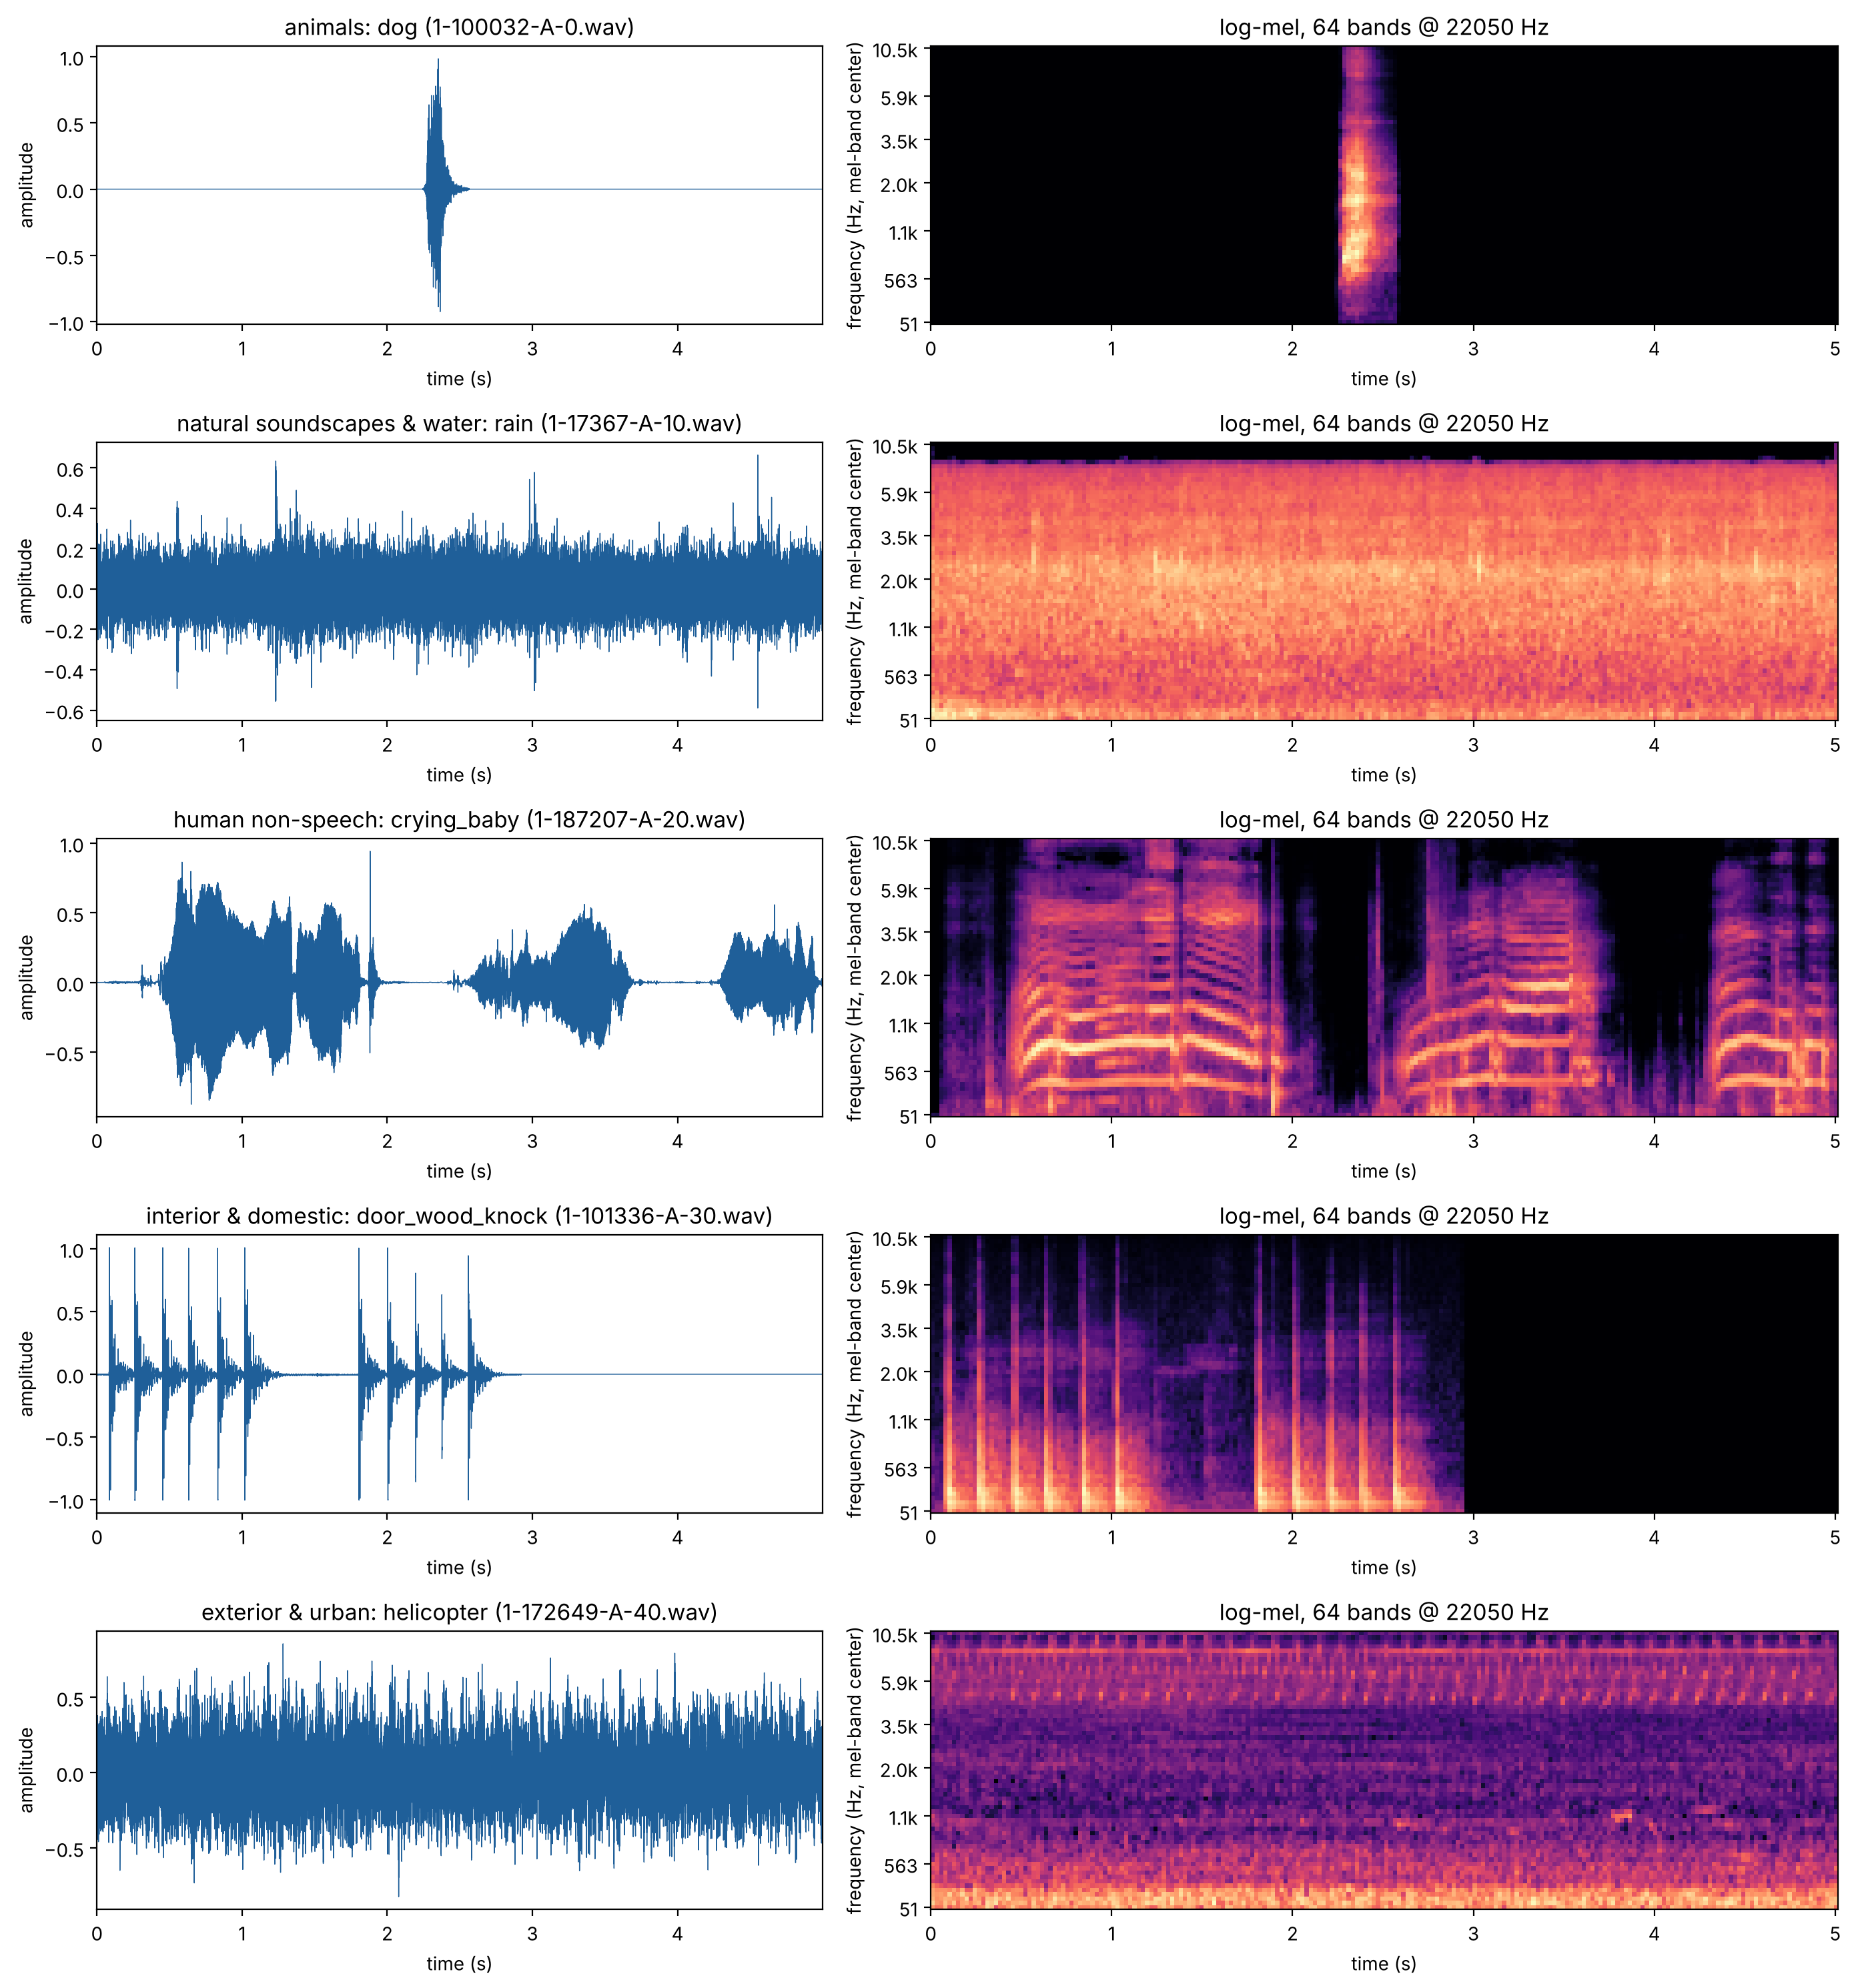

In [5]:
groups = ["animals", "natural soundscapes & water", "human non-speech", "interior & domestic", "exterior & urban"]
front = LogMel(fcfg)
fig, axes = plt.subplots(5, 2, figsize=(14, 15), gridspec_kw={"width_ratios": [1, 1.25]})
for g, name in enumerate(groups):
    i = int(np.flatnonzero((cat.targets == g * 10) & (cat.folds == 1))[0])
    wave, sr = load_audio(cat.paths[i], fcfg.sample_rate)
    wave = fix_length(wave, fcfg.num_samples)
    plot_waveform(wave.numpy(), sr, ax=axes[g, 0], title=f"{name}: {cat.class_names[cat.targets[i]]} ({cat.filenames[i]})")
    plot_logmel(front(wave).numpy(), fcfg, ax=axes[g, 1], title=f"log-mel, {fcfg.n_mels} bands @ {fcfg.sample_rate} Hz")
fig.tight_layout()